# Classical Mechanics of Harmonic Oscillators

## 1. Simple Harmonic Oscillator (SHO)

### 1.1. Governing equation & solution

Consider a block of mass $m$ attached to a spring with spring constant $k$ resting on a frictionless surface. According to Hooke's Law, the restoring force is:
$$
    F = -kx
$$
Applying Newton's second law ($F = m a = m \frac{d^2 x}{d t^2}$):
$$
    m \frac{d^2 x}{d t^2} = -kx \implies \frac{d^2 x}{d t^2} + \Omega^2 x = 0
$$
where $\Omega = \sqrt{\frac{k}{m}}$ represents the undamped natural angular frequency (in units of $\text{s}^{-1}$).   

The general solution to this linear second-order homogeneous differential equation is:
$$
    x(t) = A \cos(\Omega t) + B \sin(\Omega t)
$$
or equivalently, $x(t) = x_0 \cos(\Omega t + \phi)$, where $A, B$ (or $x_0, \phi$) are constants determined by the initial position $x(0)$ and initial velocity $v(0) = \dot{x}(0)$.

### 1.2. Potential energy & Taylor series expansion around equilibrium

For a conservative force field $F(x)$, the potential energy $U(x)$ satisfies $F(x) = -\frac{dU}{dx}$. Integrating Hooke's law gives:
$$
    U(x) = \frac{1}{2} k x^2 = \frac{1}{2} m \Omega^2 x^2
$$
**Small-Amplitude Expansion Around Equilibrium**

Any arbitrary smooth potential $U(x)$ near a stable local minimum $x_0$ can be expanded via a Taylor series:
$$
    U(x) = U(x_0) + U'(x_0)(x - x_0) + \frac{1}{2!} U''(x_0)(x - x_0)^2 + \frac{1}{3!} U'''(x_0)(x - x_0)^3 + \dots
$$
Setting $x_0 = 0$ as our origin:
1. **Constant shift:** $U(0)$ can be set to zero by choosing a reference level.
2. **Equilibrium condition:** $U'(0) = \left.\frac{dU}{dx}\right\vert{}_{x=0} = 0$ (since the force is zero at equilibrium). 
3. **Harmonic approximation:** For small displacements $x$, terms higher than second order become negligible:
$$
    U(x) \approx \frac{1}{2} U''(0) x^2
$$
Matching this with $U(x) = \frac{1}{2} k x^2$ yields the effective spring constant $k = U''(0)$, giving:
$$
    \Omega = \sqrt{\frac{U''(0)}{m}}
$$
**Application: Simple Pendulum**

For a pendulum of length $l$ and mass $m$:
$$
    U(\theta) = mgl (1 - \cos\theta)
$$
Evaluating derivatives at $\theta = 0$:
* $U'(0) = mgl \sin(0) = 0$   
* $U''(0) = mgl \cos(0) = mgl$   

Substituting $U''(0) = mgl$ into the harmonic potential $U(s) \approx \frac{1}{2} U''(0) s^2$ (where arc length $s = l\theta$):
$$
    \Omega = \sqrt{\frac{mgl}{m l^2}} = \sqrt{\frac{g}{l}}
$$

### 1.3 Total energy conversation

The mechanical energy $E$ of the simple harmonic oscillator is conserved:
$$
   E = K(t) + U(t) = \frac{1}{2} m v(t)^2 + \frac{1}{2} k x(t)^2
$$
Taking the time derivative:
$$
   \frac{dE}{dt} = m v \dot{v} + k x v = v (m a + k x) = v (0) = 0
$$

--- Simple Harmonic Oscillator (SHO) Parameters ---
Mass (m)                                : 1.0000 kg
Spring Constant (k)                     : 16.0000 N/m
Natural Frequency (Omega = sqrt(k/m))   : 4.0000 rad/s
Oscillation Period (T = 2*pi/Omega)     : 1.5708 s
Initial Position (x0)                   : 1.0000 m
Initial Velocity (v0)                   : 0.0000 m/s
Oscillation Amplitude (A)               : 1.0000 m
Total Mechanical Energy (E = 1/2 k A^2) : 8.0000 J


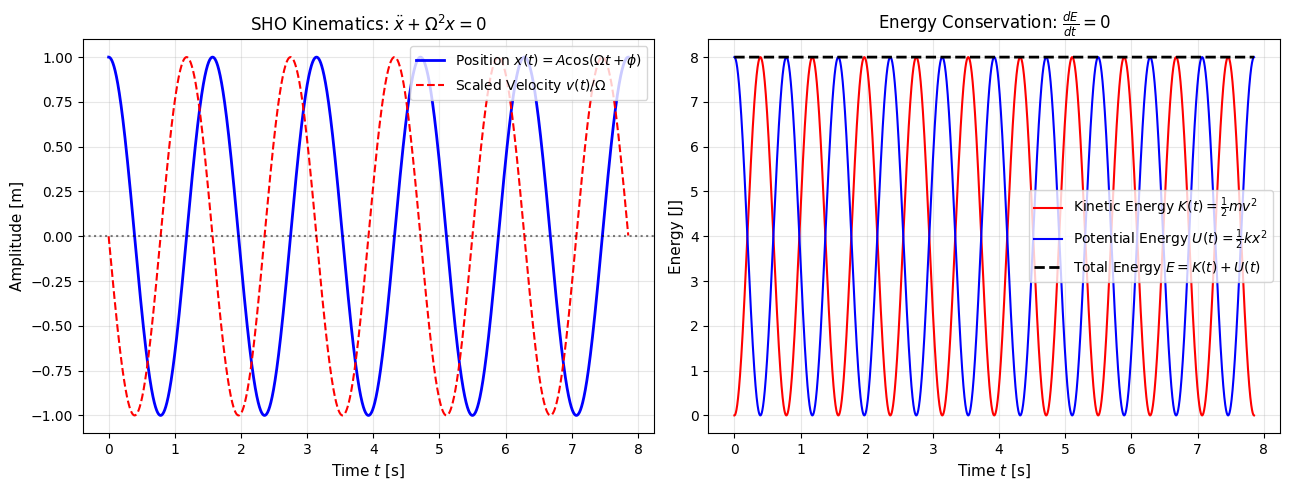

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================================
# Chapter 0, Section 0.1: Simple Harmonic Oscillator (SHO)
# Computes analytical position, velocity, and energy conservation
# =====================================================================

# 1. Physical & Numerical Parameters
# Mass of the oscillator (kg): m
m = 1.0

# Spring constant / Stiffness (N/m): k
k = 16.0

# Natural angular frequency (rad/s): \Omega = \sqrt{\frac{k}{m}}
Omega = np.sqrt(k / m)

# Period of oscillation (s): T_{\mathrm{period}} = \frac{2\pi}{\Omega}
T_period = 2.0 * np.pi / Omega

# Initial conditions: Position x(0) = x_0 [m], Velocity v(0) = v_0 [m/s]
x0 = 1.0
v0 = 0.0

# Initial phase angle (rad): \phi = \arctan\left(-\frac{v_0}{\Omega x_0}\right)
phi0 = np.arctan2(-v0 / Omega, x0)

# Initial amplitude (m): A = \sqrt{x_0^2 + \left(\frac{v_0}{\Omega}\right)^2}
A0 = np.sqrt(x0**2 + (v0 / Omega)**2)

# Time array setup: t \in [0, 5 T_{\mathrm{period}}]
t_max = 5.0 * T_period
dt = 0.001
t = np.arange(0, t_max, dt)

# 2. Analytical Trajectory Equations
# Position: x(t) = A \cos(\Omega t + \phi) = x_0 \cos(\Omega t) + \frac{v_0}{\Omega} \sin(\Omega t)
x_sho = x0 * np.cos(Omega * t) + (v0 / Omega) * np.sin(Omega * t)

# Velocity: v(t) = \frac{dx}{dt} = -\Omega x_0 \sin(\Omega t) + v_0 \cos(\Omega t)
v_sho = -x0 * Omega * np.sin(Omega * t) + v0 * np.cos(Omega * t)

# Acceleration: a(t) = \frac{d^2x}{dt^2} = -\Omega^2 x(t)
a_sho = -Omega**2 * x_sho

# 3. Energy Equations
# Kinetic Energy: K(t) = \frac{1}{2} m v(t)^2
K_sho = 0.5 * m * v_sho**2

# Potential Energy: U(t) = \frac{1}{2} k x(t)^2 = \frac{1}{2} m \Omega^2 x(t)^2
U_sho = 0.5 * k * x_sho**2

# Total Mechanical Energy: E(t) = K(t) + U(t) = \frac{1}{2} k A^2 \quad (\text{Conserved})
E_sho = K_sho + U_sho

# Print System Parameters
print("--- Simple Harmonic Oscillator (SHO) Parameters ---")
print(f"Mass (m)                                : {m:.4f} kg")
print(f"Spring Constant (k)                     : {k:.4f} N/m")
print(f"Natural Frequency (Omega = sqrt(k/m))   : {Omega:.4f} rad/s")
print(f"Oscillation Period (T = 2*pi/Omega)     : {T_period:.4f} s")
print(f"Initial Position (x0)                   : {x0:.4f} m")
print(f"Initial Velocity (v0)                   : {v0:.4f} m/s")
print(f"Oscillation Amplitude (A)               : {A0:.4f} m")
print(f"Total Mechanical Energy (E = 1/2 k A^2) : {E_sho[0]:.4f} J")

# 4. Plotting Results
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Kinematics - Displacement x(t) and Velocity v(t)
axes[0].plot(t, x_sho, 'b-', linewidth=2, label=r'Position $x(t) = A \cos(\Omega t + \phi)$')
axes[0].plot(t, v_sho / Omega, 'r--', linewidth=1.5, label=r'Scaled Velocity $v(t)/\Omega$')
axes[0].axhline(0, color='black', linestyle=':', alpha=0.5)
axes[0].set_xlabel(r'Time $t$ [s]', fontsize=11)
axes[0].set_ylabel(r'Amplitude [m]', fontsize=11)
axes[0].set_title(r'SHO Kinematics: $\ddot{x} + \Omega^2 x = 0$', fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right', fontsize=10)

# Plot 2: Energy Conservation - K(t), U(t), and Total Energy E
axes[1].plot(t, K_sho, 'r-', label=r'Kinetic Energy $K(t) = \frac{1}{2}m v^2$')
axes[1].plot(t, U_sho, 'b-', label=r'Potential Energy $U(t) = \frac{1}{2}k x^2$')
axes[1].plot(t, E_sho, 'k--', linewidth=2, label=r'Total Energy $E = K(t) + U(t)$')
axes[1].set_xlabel(r'Time $t$ [s]', fontsize=11)
axes[1].set_ylabel(r'Energy [J]', fontsize=11)
axes[1].set_title(r'Energy Conservation: $\frac{dE}{dt} = 0$', fontsize=12)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='center right', fontsize=10)

plt.tight_layout()
plt.show()

## 2. Damped Harmonic Oscillator (DHO)

### 2.1. Equation of motion & damping regimes

When viscous damping is introduced with damping coefficient $c$, the drag force is $F_{\text{drag}} = -c \frac{dx}{dt}$. Newton's second law becomes:
$$
    m \frac{d^2 x}{d t^2} = -kx - c \frac{dx}{dt} \implies \frac{d^2 x}{d t^2} + 2 \zeta \Omega_0 \frac{dx}{dt} + \Omega_0^2 x = 0
$$
where:
* $\Omega_0 = \sqrt{\frac{k}{m}}$ is the undamped natural frequency.
* $\zeta = \frac{c}{2 \sqrt{mk}} = \frac{c}{2 m \Omega_0}$ is the dimensionless damping ratio.   

Substituting $x(t) = e^{\lambda t}$ into the differential equation yields the characteristic equation:
$$
    \lambda^2 + 2\zeta\Omega_0 \lambda + \Omega_0^2 = 0 \implies \lambda_{1,2} = -\zeta \Omega_0 \pm \Omega_0 \sqrt{\zeta^2 - 1}
$$
Depending on the magnitude of $\zeta$, three distinct regimes arise: 
  
**1. Overdamped ($\zeta > 1$)**

Both roots $\lambda_{1,2}$ are real and negative. The system returns exponentially to equilibrium without oscillating:
$$
    x(t) = C_1 e^{\lambda_1 t} + C_2 e^{\lambda_2 t}
$$
**2. Critically Damped ($\zeta = 1$)**

A repeated real root $\lambda = -\Omega_0$ occurs. The system returns to equilibrium as quickly as possible without undergoing periodic oscillations:
$$
    x(t) = (C_1 + C_2 t) e^{-\Omega_0 t}
$$
**3. Underdamped ($\zeta < 1$)**

The roots are complex conjugates $\lambda = -\lambda_{\text{decay}} \pm i \omega_d$, where:
$$
    \lambda_{\text{decay}} = \zeta \Omega_0, \quad \omega_d = \Omega_0 \sqrt{1 - \zeta^2}
$$
The general solution describes exponentially decaying sinusoidal oscillations:
$$
    x(t) = A_0 e^{-\zeta \Omega_0 t} \cos(\omega_d t + \phi)
$$

### 2.2. Quality factor (Q) & energy dacay 

The Quality Factor ($Q$) measures how underdamped an oscillator is:
$$
    Q = 2\pi \times \frac{\text{Energy Stored}}{\text{Energy Lost per Cycle}} = \frac{1}{2\zeta}
$$
In the underdamped regime, total mechanical energy decays exponentially over time according to:
$$
    E(t) = E(0) e^{-2 \zeta \Omega_0 t} = E(0) e^{-\frac{\Omega_0 t}{Q}}
$$

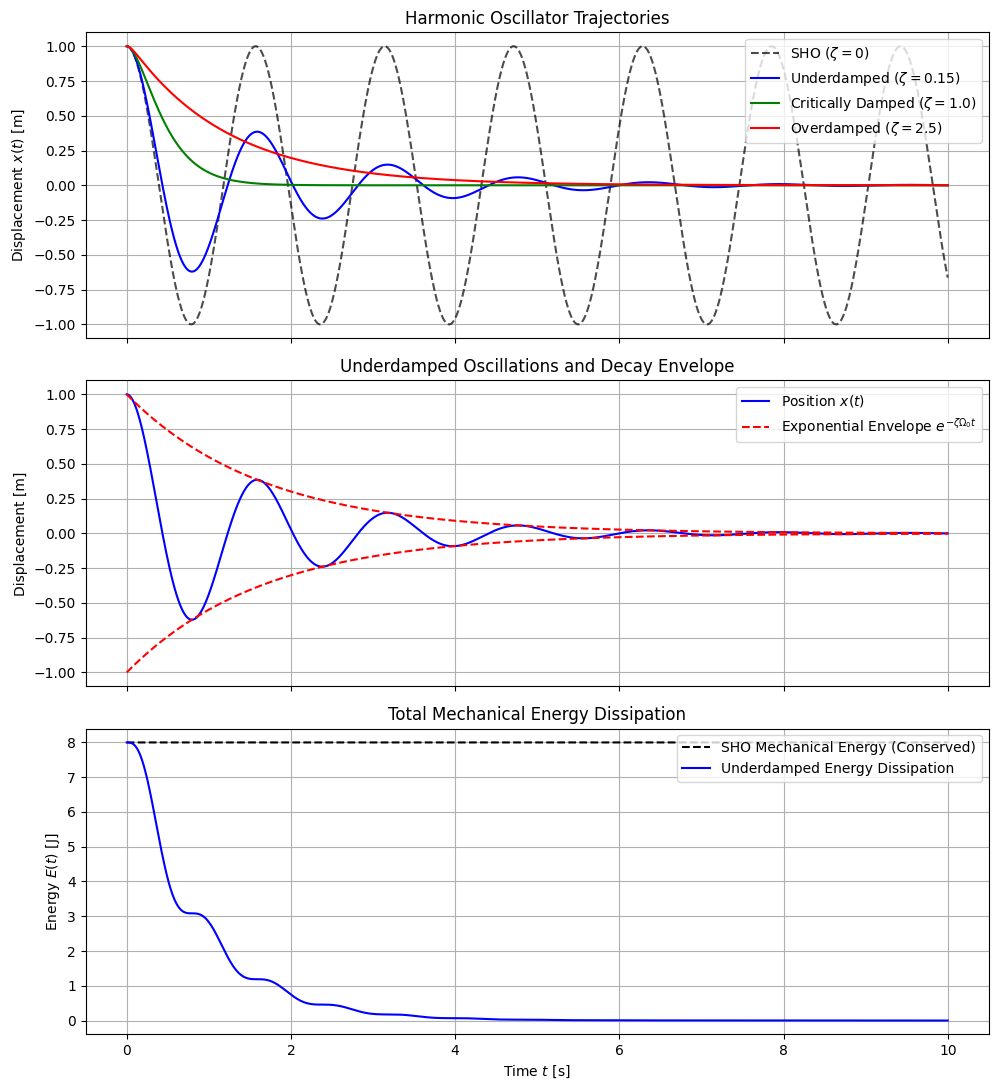

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter Configuration
m = 1.0          # Mass (kg)
k = 16.0         # Spring constant (N/m)
Omega_0 = np.sqrt(k / m)  # Natural angular frequency (rad/s)

x0 = 1.0         # Initial position (m)
v0 = 0.0         # Initial velocity (m/s)
t_max = 10.0     # Maximum simulation time (s)
dt = 0.001       # Time step (s)
t = np.arange(0, t_max, dt)

# Analytical solution for SHO
x_sho = x0 * np.cos(Omega_0 * t) + (v0 / Omega_0) * np.sin(Omega_0 * t)
v_sho = -x0 * Omega_0 * np.sin(Omega_0 * t) + v0 * np.cos(Omega_0 * t)
E_sho = 0.5 * m * v_sho**2 + 0.5 * k * x_sho**2

# Function for Underdamped Oscillator Solution (zeta < 1)
def solve_damped(t, x0, v0, m, k, zeta):
    Omega_0 = np.sqrt(k / m)
    if zeta < 1.0:
        omega_d = Omega_0 * np.sqrt(1.0 - zeta**2)
        decay = zeta * Omega_0
        A = x0
        B = (v0 + decay * x0) / omega_d
        x = np.exp(-decay * t) * (A * np.cos(omega_d * t) + B * np.sin(omega_d * t))
        v = -decay * x + np.exp(-decay * t) * (-A * omega_d * np.sin(omega_d * t) + B * omega_d * np.cos(omega_d * t))
    elif zeta == 1.0:  # Critically damped
        C1 = x0
        C2 = v0 + Omega_0 * x0
        x = (C1 + C2 * t) * np.exp(-Omega_0 * t)
        v = (C2 - Omega_0 * (C1 + C2 * t)) * np.exp(-Omega_0 * t)
    else:  # Overdamped
        gamma1 = -Omega_0 * (zeta - np.sqrt(zeta**2 - 1.0))
        gamma2 = -Omega_0 * (zeta + np.sqrt(zeta**2 - 1.0))
        C2 = (v0 - gamma1 * x0) / (gamma2 - gamma1)
        C1 = x0 - C2
        x = C1 * np.exp(gamma1 * t) + C2 * np.exp(gamma2 * t)
        v = C1 * gamma1 * np.exp(gamma1 * t) + C2 * gamma2 * np.exp(gamma2 * t)
    return x, v

# Evaluate DHO Regimes
x_under, v_under = solve_damped(t, x0, v0, m, k, zeta=0.15)
x_crit, v_crit   = solve_damped(t, x0, v0, m, k, zeta=1.00)
x_over, v_over   = solve_damped(t, x0, v0, m, k, zeta=2.50)

# Energy of underdamped system
E_under = 0.5 * m * v_under**2 + 0.5 * k * x_under**2

# Plotting Results
fig, axs = plt.subplots(3, 1, figsize=(10, 11), sharex=True)

# 1. Displacement trajectories
axs[0].plot(t, x_sho, 'k--', label=r'SHO ($\zeta=0$)', alpha=0.7)
axs[0].plot(t, x_under, 'b-', label=r'Underdamped ($\zeta=0.15$)')
axs[0].plot(t, x_crit, 'g-', label=r'Critically Damped ($\zeta=1.0$)')
axs[0].plot(t, x_over, 'r-', label=r'Overdamped ($\zeta=2.5$)')
axs[0].set_ylabel('Displacement $x(t)$ [m]')
axs[0].set_title('Harmonic Oscillator Trajectories')
axs[0].grid(True)
axs[0].legend(loc='upper right')

# 2. Underdamped envelope & energy decay
envelope = x0 * np.exp(-0.15 * Omega_0 * t)
axs[1].plot(t, x_under, 'b-', label='Position $x(t)$')
axs[1].plot(t, envelope, 'r--', label=r'Exponential Envelope $e^{-\zeta \Omega_0 t}$')
axs[1].plot(t, -envelope, 'r--')
axs[1].set_ylabel('Displacement [m]')
axs[1].set_title('Underdamped Oscillations and Decay Envelope')
axs[1].grid(True)
axs[1].legend(loc='upper right')

# 3. Energy evolution comparison
axs[2].plot(t, E_sho, 'k--', label='SHO Mechanical Energy (Conserved)')
axs[2].plot(t, E_under, 'b-', label='Underdamped Energy Dissipation')
axs[2].set_xlabel('Time $t$ [s]')
axs[2].set_ylabel('Energy $E(t)$ [J]')
axs[2].set_title('Total Mechanical Energy Dissipation')
axs[2].grid(True)
axs[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 3 Driven/Forced Harmonics Oscillator & Resonance

### 3.1. Governing equation & sinusodial driving

When a damped harmonic oscillator is subjected to an external time-dependent driving force $F_{\text{ext}}(t)$, Newton's second law takes the form:
$$
    m \frac{d^2 q}{dt^2} + c \frac{dq}{dt} + kq = F_{\text{ext}}(t)
$$
Dividing through by mass $m$ and substituting the natural frequency $\Omega_0 = \sqrt{\frac{k}{m}}$ and damping ratio $\zeta = \frac{c}{2\sqrt{mk}}$:
$$
    \frac{d^2 q}{dt^2} + 2\zeta\Omega_0 \frac{dq}{dt} + \Omega_0^2 q = \frac{F_{\text{ext}}(t)}{m}
$$
For a harmonic (sinusoidal) driving force of amplitude $F_0$ and angular frequency $\Omega$:
$$
    F_{\text{ext}}(t) = F_0 \cos(\Omega t)$$$$\frac{d^2 q}{dt^2} + 2\zeta\Omega_0 \frac{dq}{dt} + \Omega_0^2 q = \frac{F_0}{m} \cos(\Omega t)
$$

### 3.2. General solution: transients and steady-state response

The complete solution is the sum of a transient solution $q_{\text{tran}}(t)$ (which depends on initial conditions and decays exponentially due to damping) and a steady-state solution $q_{\text{steady}}(t)$ (which persists indefinitely at the driving frequency):
$$
    q(t) = q_{\text{tran}}(t) + q_{\text{steady}}(t)
$$
The steady-state response is expressed as:
$$
    q_{\text{steady}}(t) = A(\Omega) \cos(\Omega t - \phi)
$$
Amplitude and Phase ResponsesUsing phasor methods or substitution, the frequency-dependent amplitude $A(\Omega)$ and phase lag $\phi(\Omega)$ are given by:
$$
    A(\Omega) = \frac{F_0 / m}{\sqrt{(\Omega_0^2 - \Omega^2)^2 + (2\zeta\Omega_0\Omega)^2}}
$$
$$
    \phi(\Omega) = \arctan\left(\frac{2\zeta\Omega_0\Omega}{\Omega_0^2 - \Omega^2}\right)
$$

### 3.3. Resonance  phenomenon

Resonance occurs when the driving frequency $\Omega$ is tuned close to the natural frequency of the system, causing a sharp maximum in the oscillation amplitude.

Differentiating the amplitude expression $A(\Omega)$ with respect to $\Omega$ and setting it to zero yields the resonant frequency for displacement amplitude:
$$
    \Omega_{\text{res}} = \Omega_0 \sqrt{1 - 2\zeta^2}
$$
* For lightly damped systems ($\zeta \ll 1$), the resonance peak occurs almost precisely at the natural frequency: $\Omega_{\text{res}} \approx \Omega_0$.
* The maximum displacement amplitude at resonance is inversely proportional to the damping coefficient:
$$
    A(\max) \approx \frac{F_0}{2 m \zeta \Omega_0^2} = \frac{Q F_0}{m \Omega_0^2}
$$

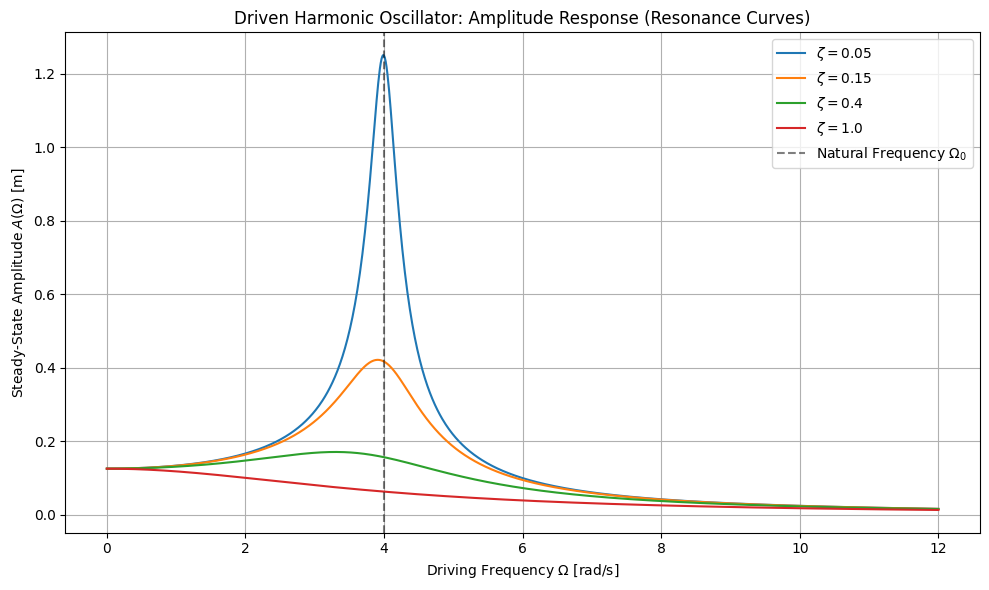

--- System Parameters ---
Natural Frequency (\Omega_0 / 2\pi) : 0.64 Hz
Spring Constant (k)                  : 16.0 N/m
Mass (m)                             : 1.0 kg


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameter Configuration
m = 1.0          # Mass (kg)
k = 16.0         # Spring constant (N/m)
Omega_0 = np.sqrt(k / m)  # Natural angular frequency (rad/s)
F0 = 2.0         # Driving force amplitude (N)

# Driving frequency range
Omega = np.linspace(0.0, 3.0 * Omega_0, 1000)

# Function to compute steady-state amplitude response
def driving_amplitude(Omega, Omega_0, zeta, F0, m):
    den = np.sqrt((Omega_0**2 - Omega**2)**2 + (2.0 * zeta * Omega_0 * Omega)**2)
    return (F0 / m) / den

# Evaluate for various damping ratios (zeta)
zetas = [0.05, 0.15, 0.40, 1.00]
plt.figure(figsize=(10, 6))

for zeta in zetas:
    A = driving_amplitude(Omega, Omega_0, zeta, F0, m)
    # Using raw f-strings (rf"...") to prevent escape sequence warnings
    plt.plot(Omega, A, label=rf'$\zeta = {zeta}$')

plt.axvline(Omega_0, color='k', linestyle='--', alpha=0.5, label=r'Natural Frequency $\Omega_0$')
plt.title(r'Driven Harmonic Oscillator: Amplitude Response (Resonance Curves)')
plt.xlabel(r'Driving Frequency $\Omega$ [rad/s]')
plt.ylabel(r'Steady-State Amplitude $A(\Omega)$ [m]')
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Clean parameter printout using raw f-strings
print(rf"--- System Parameters ---")
print(rf"Natural Frequency (\Omega_0 / 2\pi) : {Omega_0 / (2 * np.pi):.2f} Hz")
print(rf"Spring Constant (k)                  : {k} N/m")
print(rf"Mass (m)                             : {m} kg")

In this section, we simulate the quantum mechanical wavefunctions $\psi_n(x)$ and probability distributions $\vert{}\psi_n(x)\vert{}^2$ for the first few Fock states ($n = 0, 1, 2, 3$) of a quantum harmonic oscillator.

The position-space wavefunction for the $n$-th energy eigenstate is given by:
$$
    \psi_n(x) = \frac{1}{\sqrt{2^n n!}} \left(\frac{m\Omega}{\pi\hbar}\right)^{1/4} \exp\left(-\frac{m\Omega x^2}{2\hbar}\right) H_n\left(\sqrt{\frac{m\Omega}{\hbar}} x\right)
$$
where $H_n(y)$ are the physicist's Hermite polynomials.

--- Ground State Quantisation Parameters ---
Zero-point position fluctuation (x_zpf) : 2.8969e-14 m
Zero-point momentum fluctuation (p_zpf) : 1.8202e-21 kg*m/s
Ground state uncertainty product (dq*dp): 5.2729e-35 J*s (hbar/2 = 5.2729e-35)


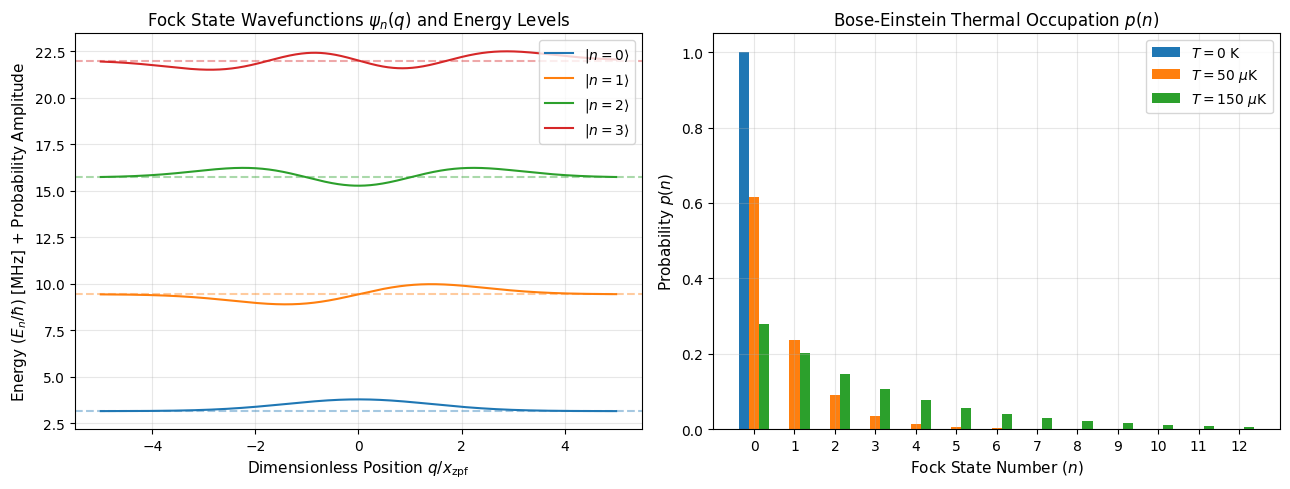

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hermite
from math import factorial

# =====================================================================
# Quantum Harmonic Oscillator: Wavefunctions and Thermal Occupancy
# =====================================================================

# 1. Physical & Numerical Parameters
hbar = 1.0545718e-34       # Reduced Planck constant (J*s)
kB = 1.380649e-23          # Boltzmann constant (J/K)
m = 1.0e-14                # Micro-resonator mass (kg)
Omega = 2.0 * np.pi * 1e6  # Resonance frequency: 1 MHz

# Zero-point fluctuation amplitudes
x_zpf = np.sqrt(hbar / (2.0 * m * Omega))
p_zpf = np.sqrt(hbar * m * Omega / 2.0)

# Spatial grid setup for position wavefunctions
q_grid = np.linspace(-5 * x_zpf, 5 * x_zpf, 1000)

# 2. Function Definitions (using raw docstrings r"""...""" to prevent escape warnings)
def fock_wavefunction(n, q, m_val, omega_val):
    r"""
    Computes the spatial wavefunction psi_n(q) = <q|n> of the n-th Fock state:
    
        psi_n(q) = (1 / sqrt(2^n * n!)) * (alpha / pi^(1/4)) * H_n(alpha * q) * exp(-alpha^2 * q^2 / 2)
        
    where alpha = 1 / (sqrt(2) * x_zpf) = sqrt(m * Omega / hbar).
    """
    alpha = np.sqrt(m_val * omega_val / hbar)
    x = alpha * q
    norm = np.sqrt(alpha / (np.sqrt(np.pi) * (2**n) * factorial(n)))
    H_n = hermite(n)(x)  # Hermite polynomial H_n(x)
    return norm * H_n * np.exp(-0.5 * x**2)

def thermal_occupancy(n_max, T, omega_val):
    r"""
    Computes Bose-Einstein thermal occupation probabilities p(n) for state |n> at temperature T:
    
        p(n) = exp(-n * hbar * Omega / (k_B * T)) / Z
        
    where Partition Function Z = sum_{n=0}^\infinity exp(-n * hbar * Omega / (k_B * T))
                             = 1 / (1 - exp(-hbar * Omega / (k_B * T)))
                             
    Mean thermal occupancy: n_th = <a^dag * a> = 1 / (exp(hbar * Omega / (k_B * T)) - 1)
    """
    if T == 0:
        p_n = np.zeros(n_max + 1)
        p_n[0] = 1.0
        return p_n
    
    beta = 1.0 / (kB * T)
    n_array = np.arange(n_max + 1)
    unnorm_p = np.exp(-beta * hbar * omega_val * n_array)
    return unnorm_p / np.sum(unnorm_p)

# 3. Compute Wavefunctions & Variances for First 4 Fock States
n_states = 4
psi_states = [fock_wavefunction(n, q_grid, m, Omega) for n in range(n_states)]

# Calculate position & momentum uncertainties for ground state |0>
dq_0 = x_zpf
dp_0 = p_zpf
uncertainty_product = dq_0 * dp_0

print(rf"--- Ground State Quantisation Parameters ---")
print(rf"Zero-point position fluctuation (x_zpf) : {x_zpf:.4e} m")
print(rf"Zero-point momentum fluctuation (p_zpf) : {p_zpf:.4e} kg*m/s")
print(rf"Ground state uncertainty product (dq*dp): {uncertainty_product:.4e} J*s (hbar/2 = {hbar/2:.4e})")

# 4. Plotting Results (using raw f-strings rf"..." for all LaTeX strings)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Wavefunctions and Energy Levels
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for n in range(n_states):
    energy_level = hbar * Omega * (n + 0.5) / hbar / 1e6  # Converted to MHz scale
    axes[0].plot(q_grid / x_zpf, psi_states[n] * np.sqrt(x_zpf) + energy_level, 
                 color=colors[n], label=rf'$|n={n}\rangle$')
    axes[0].axhline(y=energy_level, color=colors[n], linestyle='--', alpha=0.4)

axes[0].set_xlabel(rf'Dimensionless Position $q / x_{{\mathrm{{zpf}}}}$', fontsize=11)
axes[0].set_ylabel(rf'Energy $(E_n / \hbar)$ [MHz] + Probability Amplitude', fontsize=11)
axes[0].set_title(rf'Fock State Wavefunctions $\psi_n(q)$ and Energy Levels', fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right', fontsize=10)

# Plot 2: Thermal Occupation Statistics across Temperatures
n_max = 12
temperatures = [0.0, 50e-6, 150e-6]  # Temperatures in Kelvin (0 K, 50 uK, 150 uK)
bar_width = 0.25
x_indices = np.arange(n_max + 1)

for idx, T in enumerate(temperatures):
    p_n = thermal_occupancy(n_max, T, Omega)
    label_str = rf'$T = {T*1e6:.0f}\ \mu\mathrm{{K}}$' if T > 0 else rf'$T = 0\ \mathrm{{K}}$'
    axes[1].bar(x_indices + (idx - 1) * bar_width, p_n, width=bar_width, label=label_str)

axes[1].set_xlabel(rf'Fock State Number ($n$)', fontsize=11)
axes[1].set_ylabel(rf'Probability $p(n)$', fontsize=11)
axes[1].set_title(rf'Bose-Einstein Thermal Occupation $p(n)$', fontsize=12)
axes[1].set_xticks(x_indices)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()